## Explore PushT dataset

In [19]:
import matplotlib.pyplot as plt 
import numpy as np 
import zarr 

# Open the Zarr store 
dataset_path = ("/home/thanh-huynhbao/git/control_policy/dataset/pusht/pusht_cchi_v7_replay.zarr")
print(f"Dataset path:\n{dataset_path}")

store = zarr.open(dataset_path, mode="r")

# Extract raw arrays from the store
# Raw arrays include action, state and image
actions = store["data"]["action"][:]
states = store["data"]["state"][:]
images = store["data"]["img"][:]

# Extract netadata
episode_ends = store["meta"]["episode_ends"][:]

print(f"Action shape: {actions.shape}") # N x 2
print(f"State shape: {states.shape}") # N x 5
print(f"Images shape: {images.shape}") # N x (height x width x 3)
print(f"Total episodes: {len(episode_ends)}")

Dataset path:
/home/thanh-huynhbao/git/control_policy/dataset/pusht/pusht_cchi_v7_replay.zarr
Action shape: (25650, 2)
State shape: (25650, 5)
Images shape: (25650, 96, 96, 3)
Total episodes: 206


In [30]:
# Extract an episode 
episode_idx = 0
start_idx = 0 if episode_idx == 0 else episode_ends[episode_idx - 1]
end_idx = episode_ends[episode_idx]

episode_actions = actions[start_idx:end_idx]
episode_states = states[start_idx:end_idx]
episode_images = images[start_idx:end_idx]

print(f"\n--- Episode {episode_idx} Extracted ---")
print(f"Start index: {start_idx}, End index: {end_idx}")
print(f"Episode steps: {len(episode_actions)}")
print(f"Episode actions shape: {episode_actions.shape}")
print(f"Episode states shape: {episode_states.shape}")
print(f"Episode images shape: {episode_images.shape}")


--- Episode 0 Extracted ---
Start index: 0, End index: 161
Episode steps: 161
Episode actions shape: (161, 2)
Episode states shape: (161, 5)
Episode images shape: (161, 96, 96, 3)


## Visualize an episode

Visualizing Episode 0 (161 steps extracted) ... 


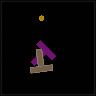

In [32]:
import io
import imageio
from IPython.display import Image, display

print(f"Visualizing Episode {episode_idx} ({len(episode_actions)} steps extracted) ... ")

# Ensure images are uint8 
if episode_images.dtype != np.uint8:
    episode_images = (episode_images * 255).astype(np.uint8)

# Export episode images 
buf = io.BytesIO() 
imageio.mimsave(buf, episode_images, format="GIF", fps=20)
buf.seek(0)

# Display the GIF 
display(Image(data=buf.read(), format="gif"))

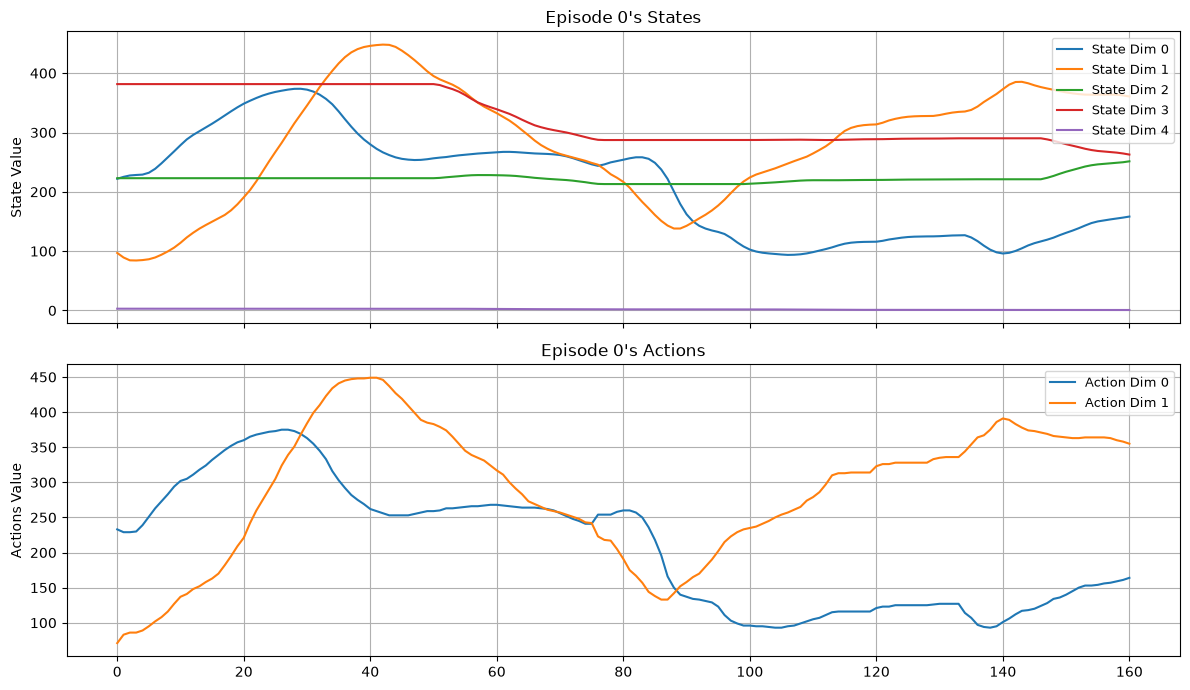

In [36]:
# Plot States and Actions time-series
fig, axes = plt.subplots(2, 1, figsize=(12,7), sharex=True)

# Plot States (5 dimensions: e.g., agent position, block pose)
for i in range(episode_states.shape[1]):
    axes[0].plot(episode_states[:,i], label=f"State Dim {i}")
axes[0].set_title(f"Episode {episode_idx}'s States")
axes[0].set_ylabel("State Value")
axes[0].legend(loc="upper right", fontsize=9)
axes[0].grid(True)
# Plot Actions (2 dimensions)
for i in range(episode_actions.shape[1]):
    axes[1].plot(episode_actions[:,i], label=f"Action Dim {i}")
axes[1].set_title(f"Episode {episode_idx}'s Actions")
axes[1].set_ylabel("Actions Value")
axes[1].legend(loc="upper right", fontsize=9)
axes[1].grid(True)

plt.tight_layout()
plt.show()